# Week 11 · Advanced Social Media Mining with RNN, LSTM and GRU
**ISB02306504 – Social Media Mining** · Information Systems for Business · Odd Semester 2026/2027

In week 6 we classified sentiment with TF-IDF + linear models: they see *which* words occur, not *in what order*. This week we train **sequence models** that read a post token by token, then join their predictions with the **network** from weeks 9–10.

| Part | What we do | Slide topics |
|---|---|---|
| 0–1 | Setup; why order matters | Sequence Thinking, Pipeline |
| 2 | Data, splits, tokenizer fitted on train only, padding & masking | Training Workflow; Padding, Masking & Sequence Length |
| 3 | Inside the cells with NumPy: hidden state, unrolling, fading memory, parameter counts | RNN Hidden State, RNN Equation, Unrolling, Strengths & Weaknesses, LSTM vs GRU |
| 4 | TF-IDF baseline (the bar to beat) | Sequence Thinking |
| 5 | Keras: SimpleRNN vs LSTM vs GRU vs BiLSTM, fair comparison, overfitting | LSTM/GRU Text Classifier, Bidirectional LSTM, Compare Recurrent Architectures, Overfitting |
| 6 | **Hyperparameter tuning**: random search on the validation set | Training Workflow, Overfitting |
| 7 | Final test, error analysis, a look inside the LSTM gates | Training Workflow, Inside an LSTM Cell |
| 8 | Integrating sequence NLP and SNA: sentiment by community, negative bridges | Integrating Sequence NLP & SNA (all) |

**Data:** *Twitter US Airline Sentiment* (14,640 tweets to six US airlines, Feb 2015, labelled negative / neutral / positive), read directly from a public GitHub repository with pandas (1 MB zip).

**Runtime:** use a Colab **GPU** (*Runtime → Change runtime type → T4 GPU*).

---
## 0. Setup
Colab ships with Keras 3 and TensorFlow. We pick the backend explicitly *before* importing Keras.

In [ ]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")       # Keras 3 can also run on "jax" or "torch"

import re, time, json, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import keras
from keras import layers
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

FAST_DEMO = False          # True → fewer seeds and tuning trials for a short live demo
SEED = 42
keras.utils.set_random_seed(SEED)           # seeds Python, NumPy and the backend in one call
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9})
BLUE, ORANGE, GREY, GREEN, YELLOW = "#2a78d6", "#eb6834", "#8a8984", "#1baf7a", "#eda100"
CLASS_COLORS = {"negative": ORANGE, "neutral": GREY, "positive": BLUE}

try:
    import tensorflow as tf
    gpus = tf.config.list_physical_devices("GPU")
except Exception:
    gpus = []
print("Keras", keras.__version__, "| backend:", keras.backend.backend(), "| GPU:", gpus or "none (CPU)")

Keras 3.13.2 | backend: tensorflow | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Reproducibility note.** `set_random_seed` fixes the initial weights and the data shuffling, but GPU kernels are not always deterministic, so a rerun can differ in the third decimal. That is one reason we compare models over **more than one seed** in part 5.

---
## 1. Why word order matters  *(slide: Sequence Thinking)*

In [ ]:
sentences = ["produk ini bagus",
             "produk ini tidak bagus",
             "awalnya jelek, tapi akhirnya bagus",
             "awalnya bagus, tapi akhirnya jelek"]
bow = CountVectorizer().fit(sentences)
display(pd.DataFrame(bow.transform(sentences).toarray(), index=sentences, columns=bow.get_feature_names_out()))
same = (bow.transform([sentences[2]]) != bow.transform([sentences[3]])).nnz == 0
print("Do the last two sentences get the SAME bag-of-words vector?", same)

,akhirnya,awalnya,bagus,ini,jelek,produk,tapi,tidak
produk ini bagus,0,0,1,1,0,1,0,0
produk ini tidak bagus,0,0,1,1,0,1,0,1
"awalnya jelek, tapi akhirnya bagus",1,1,1,0,1,0,1,0
"awalnya bagus, tapi akhirnya jelek",1,1,1,0,1,0,1,0


Do the last two sentences get the SAME bag-of-words vector? True


Bag-of-words *can* see `tidak` (row 2 differs from row 1), but the last two rows are **identical** although they mean opposite things: what matters is which evaluation comes *after* "tapi". N-grams help a little; sequence models read the tokens in order and keep a running summary (the slide's line: *Bag-of-Words can see the words. Sequence models can also model their order and evolving context*).

The pipeline we will build (slide: *Pipeline: From Text to a Sequence Model*):

`raw text → token IDs → padding → embedding → RNN / LSTM / GRU → classifier`

---
## 2. Data
### 2.1 Load and look

In [ ]:
TWEETS_URL = "https://github.com/albahnsen/AppliedDeepLearningClass/raw/master/datasets/Tweets.zip"
raw = pd.read_csv(TWEETS_URL)
print(raw.shape)
display(raw[["tweet_id", "name", "airline", "airline_sentiment", "text"]].head(4))

(14640, 15)


,tweet_id,name,airline,airline_sentiment,text
0,570306133677760513,cairdin,Virgin America,neutral,@VirginAmerica What @dhepburn said.
1,570301130888122368,jnardino,Virgin America,positive,@VirginAmerica plus you've added commercials to the experience... tacky.
2,570301083672813571,yvonnalynn,Virgin America,neutral,@VirginAmerica I didn't today... Must mean I need to take another trip!
3,570301031407624196,jnardino,Virgin America,negative,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &amp; they ..."


14,640 rows → 14,427 after removing duplicate ids and duplicate texts


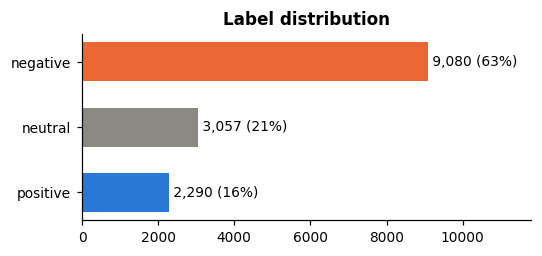

In [ ]:
df = raw.drop_duplicates("tweet_id").copy()
df = df.drop_duplicates("text")                          # identical texts would leak between splits
df = df.rename(columns={"airline_sentiment": "label", "name": "user"})
df["user"] = df["user"].str.lower()
print(f"{len(raw):,} rows → {len(df):,} after removing duplicate ids and duplicate texts")

counts = df["label"].value_counts().reindex(CLASS_COLORS)
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.barh(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index], height=0.6)
for y, v in enumerate(counts.values):
    ax.text(v, y, f" {v:,} ({v / len(df):.0%})", va="center")
ax.invert_yaxis(); ax.set_title("Label distribution"); ax.set_xlim(0, counts.max() * 1.3)
plt.tight_layout(); plt.show()

Negative tweets are the majority. Accuracy would reward a model that ignores the small classes, so we select models by **macro-F1**, which gives neutral and positive the same weight as negative (slide: *Example: GRU Text Classifier*).

### 2.2 Light, task-aware cleaning
Lessons from week 5: every tweet mentions an airline (`@united`), which tells the model *which airline*, not *what sentiment*. We replace handles and links with placeholders, lowercase, and keep negations, `!`, `?` and emoticons.

In [ ]:
TOKEN_RE = re.compile(r"<user>|<url>|[a-z]+(?:'[a-z]+)?|[!?]|[:;]-?[()dp]")

def clean(text):
    t = text.lower()
    t = re.sub(r"https?://\S+", " <url> ", t)
    t = re.sub(r"@\w+", " <user> ", t)
    t = re.sub(r"&amp;", "&", t)
    return t

def tokenize(text):
    return TOKEN_RE.findall(clean(text))

df["tokens"] = df["text"].map(tokenize)
for t in df["text"].sample(3, random_state=3):
    print(t, "\n   →", tokenize(t))

@SouthwestAir thank you for your help resolving my problem Shannon ROCKS - even though Rhonda didn't !! 
   → ['<user>', 'thank', 'you', 'for', 'your', 'help', 'resolving', 'my', 'problem', 'shannon', 'rocks', 'even', 'though', 'rhonda', "didn't", '!', '!']
@JetBlue's CEO battles to appease passengers and Wall Street - Waterbury Republican American http://t.co/FFc13zYGJS 
   → ['<user>', 's', 'ceo', 'battles', 'to', 'appease', 'passengers', 'and', 'wall', 'street', 'waterbury', 'republican', 'american', '<url>']
@AmericanAir If you care, could you have someone call me to explain what is going on. 
   → ['<user>', 'if', 'you', 'care', 'could', 'you', 'have', 'someone', 'call', 'me', 'to', 'explain', 'what', 'is', 'going', 'on']


### 2.3 Split first, then build the vocabulary  *(slide: Training Workflow)*
Train / validation / test = 70 / 15 / 15, stratified by label. The **test set stays untouched** until part 7. All comparisons and all tuning use the **validation** set.

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

CLASSES = ["negative", "neutral", "positive"]
label_to_id = {c: i for i, c in enumerate(CLASSES)}
y_train, y_val, y_test = (d["label"].map(label_to_id).values for d in (train_df, val_df, test_df))

display(pd.DataFrame({name: d["label"].value_counts(normalize=True).reindex(CLASSES)
                      for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]})
        .T.assign(n=[len(train_df), len(val_df), len(test_df)]).style.format("{:.1%}").format("{:,.0f}", subset=["n"]))

label,negative,neutral,positive,n
train,62.9%,21.2%,15.9%,"10,098"
validation,62.9%,21.2%,15.9%,"2,164"
test,63.0%,21.2%,15.8%,"2,165"


In [ ]:
PAD, OOV = 0, 1
MIN_FREQ = 2

counter = Counter(tok for toks in train_df["tokens"] for tok in toks)          # TRAIN ONLY
vocab = ["<pad>", "<oov>"] + sorted(w for w, c in counter.items() if c >= MIN_FREQ)
word_to_id = {w: i for i, w in enumerate(vocab)}
VOCAB_SIZE = len(vocab)

def encode(tokens):
    return [word_to_id.get(t, OOV) for t in tokens]

for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    ids = [i for toks in d["tokens"] for i in encode(toks)]
    print(f"{name:<10} OOV rate: {np.mean(np.array(ids) == OOV):.1%}")
print(f"Vocabulary: {VOCAB_SIZE:,} tokens (words seen ≥ {MIN_FREQ} times in train, plus <pad> and <oov>)")

train      OOV rate: 2.6%
validation OOV rate: 4.2%
test       OOV rate: 4.2%
Vocabulary: 4,730 tokens (words seen ≥ 2 times in train, plus <pad> and <oov>)


Building the vocabulary from all data would leak information from the test set into the model's input space. With the train-only vocabulary, unseen validation/test words map to `<oov>`, exactly as new posts will in production.

### 2.4 Sequence length, padding and masking  *(slide: Padding, Masking & Sequence Length)*

{'count': 10098.0, 'mean': 18.0, 'std': 6.8, 'min': 2.0, '50%': 19.0, '90%': 26.0, '95%': 27.0, '99%': 30.0, 'max': 36.0}
MAX_LEN = 29 → 1.2% of training tweets get truncated


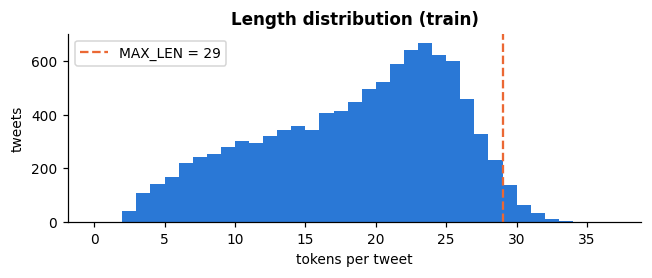

In [ ]:
lengths = train_df["tokens"].str.len()
MAX_LEN = int(np.percentile(lengths, 95)) + 2
print(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_dict())
print(f"MAX_LEN = {MAX_LEN} → {np.mean(lengths > MAX_LEN):.1%} of training tweets get truncated")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(lengths, bins=range(0, lengths.max() + 2), color=BLUE)
ax.axvline(MAX_LEN, color=ORANGE, ls="--", label=f"MAX_LEN = {MAX_LEN}")
ax.set_xlabel("tokens per tweet"); ax.set_ylabel("tweets"); ax.legend(); ax.set_title("Length distribution (train)")
plt.tight_layout(); plt.show()

In [ ]:
def to_matrix(token_lists, max_len=MAX_LEN):
    """Encode, truncate long posts (keep the first max_len tokens) and pad short ones at the END."""
    X = np.full((len(token_lists), max_len), PAD, dtype="int32")
    for row, toks in enumerate(token_lists):
        ids = encode(toks)[:max_len]
        X[row, :len(ids)] = ids
    return X

X_train, X_val, X_test = (to_matrix(d["tokens"].tolist()) for d in (train_df, val_df, test_df))
print("X_train shape:", X_train.shape)
example = train_df["tokens"].iloc[0]
print("tokens :", example)
print("ids    :", X_train[0].tolist())
print("mask   :", (X_train[0] != PAD).astype(int).tolist())

X_train shape: (10098, 29)
tokens : ['<user>', "i've", 'been', 'on', 'hold', 'for', 'minutes', 'just', 'to', 'get', 'a', 'receipt', 'i', 'know', 'you', 'guys', 'are', 'busy', 'but', 'i', 'think', "it's", 'time', 'to', 'higher', 'more', 'staff', '!']
ids    : [12, 2065, 393, 2867, 1976, 1658, 2642, 2283, 4217, 1765, 14, 3338, 2061, 2319, 4703, 1862, 238, 564, 565, 2061, 4170, 2217, 4203, 4217, 1960, 2677, 3922, 2, 0]
mask   : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]


- **Padding** adds `0`s so every row has the same length and tweets can be batched.
- **Masking** (`mask_zero=True` in the Embedding layer) tells the recurrent layer to *skip* those zeros, so the final state is the state after the last real word, not after twenty pads.
- **Pad at the end** ("post" padding): with masking, Keras' fast cuDNN implementation of LSTM/GRU on GPU requires right-padded sequences.
- **MAX_LEN** from the length distribution: long enough for 95% of tweets, short enough to keep computation low.

---
## 3. Inside the recurrent cell, with NumPy  *(slides: RNN Hidden State, RNN Equation, Unrolling)*
Before Keras hides everything behind one line, we compute a simple RNN by hand. At each timestep:

$$h_t = \tanh(W_x\,x_t + W_h\,h_{t-1} + b)$$

- $x_t$: embedding of the current token, $h_{t-1}$: memory from the previous step, $h_t$: the updated running summary.
- The **same** $W_x, W_h, b$ are reused at every position (parameter sharing).

The weights below are random, so the numbers have no meaning yet; the point is the mechanics and the shapes.

In [ ]:
rng = np.random.default_rng(0)
toy_tokens = ["delivery", "tidak", "terlalu", "lama"]
d, u = 4, 3                                         # embedding size, hidden units
E_toy = {w: rng.normal(0, 1, d) for w in toy_tokens}
W_x, W_h, b = rng.normal(0, 0.6, (u, d)), rng.normal(0, 0.6, (u, u)), np.zeros(u)

h = np.zeros(u)                                     # h_0: empty memory
states = []
for t, w in enumerate(toy_tokens, start=1):
    h = np.tanh(W_x @ E_toy[w] + W_h @ h + b)
    states.append(h)
    print(f"t={t}  x_t = emb('{w}')  →  h_t = {np.round(h, 3)}")

print(f"\nShapes: W_x {W_x.shape}, W_h {W_h.shape}, b {b.shape}  → {W_x.size + W_h.size + b.size} parameters, whatever the sentence length")

t=1  x_t = emb('delivery')  →  h_t = [ 0.205 -0.338 -0.276]
t=2  x_t = emb('tidak')  →  h_t = [ 0.796 -0.066 -0.865]
t=3  x_t = emb('terlalu')  →  h_t = [ 0.564 -0.801  0.226]
t=4  x_t = emb('lama')  →  h_t = [-0.348  0.398 -0.461]

Shapes: W_x (3, 4), W_h (3, 3), b (3,)  → 24 parameters, whatever the sentence length


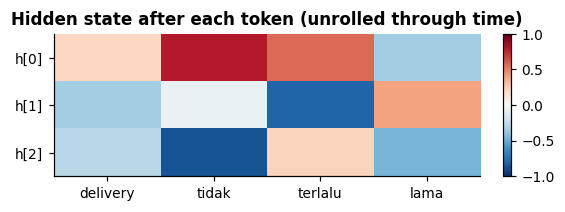

In [ ]:
fig, ax = plt.subplots(figsize=(5.2, 2.0))
im = ax.imshow(np.array(states).T, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(toy_tokens)), toy_tokens); ax.set_yticks(range(u), [f"h[{i}]" for i in range(u)])
ax.set_title("Hidden state after each token (unrolled through time)")
plt.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); plt.show()

Each column is the state after reading one more word. The state is a vector, not a readable sentence (slide: *the hidden state is not a human-readable sentence*).

### 3.1 Why early words fade in a simple RNN  *(slide: RNN Strengths and Weaknesses)*
How much does the final state still depend on the **first** word? Mathematically, the sensitivity $\partial h_T / \partial h_1$ is a product of one Jacobian per step, $\prod_t \operatorname{diag}(1-h_t^2)\,W_h$. When those factors are smaller than 1, the product shrinks exponentially with distance; this is the **vanishing gradient** problem. LSTM's cell state is updated *additively*, $c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t$, so along that path the factor is just the forget gate $f_t$, which the model can learn to keep close to 1.

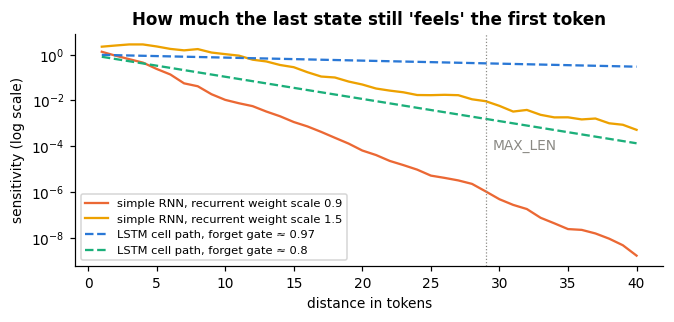

In [ ]:
def rnn_sensitivity(T, units=32, scale=0.9, seed=0):
    """||dh_T / dh_1|| for a random tanh RNN fed random inputs."""
    r = np.random.default_rng(seed)
    W = r.normal(0, scale / np.sqrt(units), (units, units))
    Wx = r.normal(0, 1 / np.sqrt(units), (units, units))
    h, J = np.zeros(units), np.eye(units)
    norms = []
    for _ in range(T):
        h = np.tanh(W @ h + Wx @ r.normal(0, 1, units))
        J = np.diag(1 - h ** 2) @ W @ J
        norms.append(np.linalg.norm(J, 2))
    return np.array(norms)

T = 40
steps = np.arange(1, T + 1)
fig, ax = plt.subplots(figsize=(6.2, 3))
for scale, c in [(0.9, ORANGE), (1.5, YELLOW)]:
    ax.semilogy(steps, rnn_sensitivity(T, scale=scale), color=c, label=f"simple RNN, recurrent weight scale {scale}")
for f, c in [(0.97, BLUE), (0.80, GREEN)]:
    ax.semilogy(steps, f ** steps, color=c, ls="--", label=f"LSTM cell path, forget gate ≈ {f}")
ax.axvline(MAX_LEN, color=GREY, lw=0.8, ls=":")
ax.text(MAX_LEN + 0.5, 0.5, "MAX_LEN", color=GREY, transform=ax.get_xaxis_transform())
ax.set_xlabel("distance in tokens"); ax.set_ylabel("sensitivity (log scale)")
ax.set_title("How much the last state still 'feels' the first token")
ax.legend(fontsize=7.5, loc="lower left"); plt.tight_layout(); plt.show()

Read the plot as intuition, not as a measurement of our trained models: the RNN curves use random weights. Two takeaways:
1. A simple RNN's memory of early tokens decays roughly exponentially, faster or slower depending on its weights.
2. A gated cell can **choose** to keep information (forget gate near 1) or drop it. That choice is learned from data.

Tweets are short (≈ 20 tokens), so the simple RNN is not hopeless here; that is exactly why we will test it rather than assume.

### 3.2 Counting parameters  *(slide: LSTM vs GRU)*
For input size $d$ (embedding dimension) and $u$ units:

| Layer | Parameters | Why |
|---|---|---|
| SimpleRNN | $u\,(d + u + 1)$ | one transformation |
| LSTM | $4u\,(d + u + 1)$ | input, forget, output gates + candidate |
| GRU (Keras 3 default `reset_after=True`) | $3u\,(d + u + 2)$ | update, reset gates + candidate; two bias vectors |
| Bidirectional(X) | $2 \times$ X | one forward + one backward copy |

In [ ]:
def recurrent_params(kind, d, u):
    return {"SimpleRNN": u * (d + u + 1), "LSTM": 4 * u * (d + u + 1), "GRU": 3 * u * (d + u + 2)}[kind]

def total_params(kind, vocab, d, u, n_classes=3, bidirectional=False):
    rec = recurrent_params(kind, d, u) * (2 if bidirectional else 1)
    out_in = u * (2 if bidirectional else 1)
    return vocab * d + rec + out_in * n_classes + n_classes

rows = []
for kind in ["SimpleRNN", "GRU", "LSTM"]:
    rows.append({"layer": kind, "recurrent params (d=64, u=64)": recurrent_params(kind, 64, 64),
                 "whole model incl. embedding": total_params(kind, VOCAB_SIZE, 64, 64)})
param_table = pd.DataFrame(rows).set_index("layer")
display(param_table.style.format("{:,}"))
print(f"Embedding alone: {VOCAB_SIZE:,} × 64 = {VOCAB_SIZE * 64:,} parameters")

,"recurrent params (d=64, u=64)",whole model incl. embedding
layer,,
SimpleRNN,"8,256","311,171"
GRU,"24,960","327,875"
LSTM,"33,024","335,939"


Embedding alone: 4,730 × 64 = 302,720 parameters


Two lessons: GRU sits between SimpleRNN and LSTM (fewer gates), and for a small text model the **embedding table is usually the largest part**. A bigger vocabulary costs more parameters than more units do. We check these formulas against Keras in part 5.

---
## 4. Baseline first: TF-IDF + logistic regression
A sequence model is only worth its cost if it beats a strong, cheap baseline trained on the **same split** and the **same tokens**. We also use this to show the simplest form of tuning: a small grid over one hyperparameter, judged on validation.

In [ ]:
join = lambda toks: " ".join(toks)
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                        ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(train_df["tokens"].map(join))          # fit on train only
Xva_tfidf = tfidf.transform(val_df["tokens"].map(join))
Xte_tfidf = tfidf.transform(test_df["tokens"].map(join))

grid = []
for C in [0.25, 0.5, 1, 2, 4, 8]:
    lr_model = LogisticRegression(C=C, class_weight="balanced", max_iter=2000).fit(Xtr_tfidf, y_train)
    grid.append({"C": C, "val_macro_f1": f1_score(y_val, lr_model.predict(Xva_tfidf), average="macro")})
grid = pd.DataFrame(grid)
best_C = grid.loc[grid["val_macro_f1"].idxmax(), "C"]
display(grid.style.format({"val_macro_f1": "{:.3f}"}).highlight_max(subset=["val_macro_f1"], color="#d6e6fa"))

baseline = LogisticRegression(C=best_C, class_weight="balanced", max_iter=2000).fit(Xtr_tfidf, y_train)
BASELINE_VAL_F1 = f1_score(y_val, baseline.predict(Xva_tfidf), average="macro")
print(f"TF-IDF (1–2 grams) + LR, C={best_C}: validation macro-F1 = {BASELINE_VAL_F1:.3f}  ← the bar to beat")

,C,val_macro_f1
0,0.250000,0.731
1,0.500000,0.741
2,1.000000,0.752
3,2.000000,0.755
4,4.000000,0.751
5,8.000000,0.749


TF-IDF (1–2 grams) + LR, C=2.0: validation macro-F1 = 0.755  ← the bar to beat


Bigrams already capture short-range order (`not good`, `on time`). The question for the recurrent models is whether *longer* context adds anything on top.

---
## 5. Recurrent classifiers in Keras  *(slides: Example LSTM / GRU Text Classifier, Compare Recurrent Architectures)*
### 5.1 One model builder for every architecture
Fair comparison means everything except the recurrent layer stays fixed: same tokens, same split, same embedding size, same output layer, same training budget. A single builder function enforces that.

In [ ]:
N_CLASSES = len(CLASSES)
RNN_LAYERS = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}

def make_model(kind="LSTM", emb_dim=64, units=64, dropout=0.3, lr=1e-3, bidirectional=False):
    recurrent = RNN_LAYERS[kind](units)
    if bidirectional:
        recurrent = layers.Bidirectional(recurrent)
    model = keras.Sequential([
        layers.Input(shape=(MAX_LEN,), dtype="int32"),
        layers.Embedding(VOCAB_SIZE, emb_dim, mask_zero=True),     # token IDs → dense vectors, pads masked
        recurrent,                                                  # sequence → one vector (last state)
        layers.Dropout(dropout),
        layers.Dense(N_CLASSES, activation="softmax"),              # 3-class output
    ], name=f"{'Bi' if bidirectional else ''}{kind}")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",            # integer labels 0/1/2
                  metrics=["accuracy"])
    return model

demo = make_model("LSTM", emb_dim=64, units=64)
demo.summary()

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 29, 64)         │       302,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 335,939 (1.28 MB)

 Trainable params: 335,939 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Self-check: Keras parameter counts must match the formulas from 3.2
checks = []
for kind in ["SimpleRNN", "LSTM", "GRU"]:
    for bi in [False, True]:
        m = make_model(kind, emb_dim=64, units=64, bidirectional=bi)
        checks.append({"model": m.name, "keras": m.count_params(),
                       "formula": total_params(kind, VOCAB_SIZE, 64, 64, bidirectional=bi)})
checks = pd.DataFrame(checks).assign(match=lambda t: t["keras"] == t["formula"])
display(checks.style.format({"keras": "{:,}", "formula": "{:,}"}))
assert checks["match"].all(), "parameter formula mismatch: check the Keras version's GRU reset_after default"
del demo, m

,model,keras,formula,match
0,SimpleRNN,"311,171","311,171",True
1,BiSimpleRNN,"319,619","319,619",True
2,LSTM,"335,939","335,939",True
3,BiLSTM,"369,155","369,155",True
4,GRU,"327,875","327,875",True
5,BiGRU,"353,027","353,027",True


Choices worth defending in class:
- **`mask_zero=True`** so padded positions are skipped (slide: Padding, Masking).
- **Softmax with one unit per class + `sparse_categorical_crossentropy`**: the slide's binary example uses `Dense(1, sigmoid)`; for 3 classes we follow the GRU slide.
- **Dropout after the recurrent layer** rather than `recurrent_dropout=`: recurrent dropout disables the fast cuDNN kernel on GPU and can make training several times slower.
- The model returns only the **last** hidden state (`return_sequences=False`), which is what a post-level classifier needs.

### 5.2 Training helper: early stopping + class weights

In [ ]:
classes_present = np.unique(y_train)
CLASS_WEIGHT = {int(k): float(w) for k, w in
                zip(classes_present, compute_class_weight("balanced", classes=classes_present, y=y_train))}
print("class weights:", {CLASSES[k]: round(v, 2) for k, v in CLASS_WEIGHT.items()})

MAX_EPOCHS = 15

def macro_f1(model, X, y):
    return f1_score(y, model.predict(X, batch_size=512, verbose=0).argmax(1), average="macro")

def train(config, seed=SEED, epochs=MAX_EPOCHS, early_stop=True, use_class_weight=True, verbose=0):
    """Build, fit on train, monitor validation. Returns model, history and a summary row."""
    config = dict(config)
    batch_size = config.pop("batch_size", 64)
    keras.utils.set_random_seed(seed)
    model = make_model(**config)
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                               restore_best_weights=True)] if early_stop else []
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                     batch_size=batch_size, class_weight=CLASS_WEIGHT if use_class_weight else None,
                     callbacks=callbacks, verbose=verbose)
    seconds = time.time() - t0
    val_loss = hist.history["val_loss"]
    row = {**config, "batch_size": batch_size, "seed": seed,
           "val_macro_f1": macro_f1(model, X_val, y_val),
           "best_epoch": int(np.argmin(val_loss)) + 1, "epochs_run": len(val_loss),
           "params": model.count_params(), "seconds": round(seconds, 1)}
    return model, hist.history, row

class weights: {'negative': 0.53, 'neutral': 1.57, 'positive': 2.1}


- **EarlyStopping on `val_loss`, `restore_best_weights=True`**: training stops two epochs after validation loss stops improving and *rolls back* to the best epoch, so we keep the best model, not the last one.
- **Class weights** make a mistake on a rare class cost more, which usually lifts macro-F1 at a small cost in accuracy.
- Every run calls `set_random_seed(seed)` first, so a configuration is reproducible and the only thing that differs between architectures is the architecture.

### 5.3 Fair comparison: RNN vs LSTM vs GRU vs BiLSTM, two seeds each

In [ ]:
ARCHS = {"SimpleRNN": dict(kind="SimpleRNN"), "GRU": dict(kind="GRU"),
         "LSTM": dict(kind="LSTM"), "BiLSTM": dict(kind="LSTM", bidirectional=True)}
BASE = dict(emb_dim=64, units=64, dropout=0.3, lr=1e-3, batch_size=64)
SEEDS = [42] if FAST_DEMO else [42, 7]

compare_rows, histories, models_cmp = [], {}, {}
t_all = time.time()
for name, arch in ARCHS.items():
    for seed in SEEDS:
        model, hist, row = train({**BASE, **arch}, seed=seed)
        compare_rows.append({"model": name, **row})
        if seed == SEEDS[0]:
            histories[name], models_cmp[name] = hist, model
        print(f"{name:<10} seed {seed:<3} val macro-F1 {row['val_macro_f1']:.3f} | best epoch {row['best_epoch']:>2} | {row['seconds']:>5.1f}s")
print(f"total {time.time() - t_all:.0f}s")
compare = pd.DataFrame(compare_rows)

SimpleRNN  seed 42  val macro-F1 0.700 | best epoch  3 |  13.6s
SimpleRNN  seed 7   val macro-F1 0.710 | best epoch  2 |  11.4s


GRU        seed 42  val macro-F1 0.711 | best epoch  2 |  15.5s
GRU        seed 7   val macro-F1 0.717 | best epoch  2 |   6.6s
LSTM       seed 42  val macro-F1 0.720 | best epoch  2 |   6.9s
LSTM       seed 7   val macro-F1 0.741 | best epoch  2 |   7.5s
BiLSTM     seed 42  val macro-F1 0.734 | best epoch  2 |   8.6s
BiLSTM     seed 7   val macro-F1 0.711 | best epoch  2 |   9.4s
total 86s


,val_f1_mean,val_f1_std,params,best_epoch,seconds
model,,,,,
SimpleRNN,0.705,0.008,"311,171",2.5,12.5
GRU,0.714,0.004,"327,875",2.0,11.1
LSTM,0.731,0.015,"335,939",2.0,7.2
BiLSTM,0.722,0.017,"369,155",2.0,9.0
TF-IDF + LR,0.755,–,"68,523",–,–


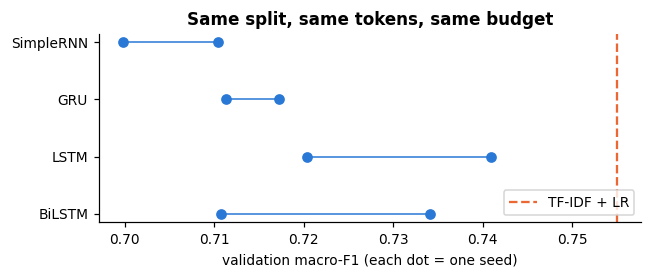

Best recurrent model: LSTM (0.731); worst: SimpleRNN (0.705).
Gap between best and worst architecture: 0.026; typical seed-to-seed std: 0.011.
Best recurrent vs TF-IDF baseline: -0.024


In [ ]:
summary = (compare.groupby("model", sort=False)
           .agg(val_f1_mean=("val_macro_f1", "mean"), val_f1_std=("val_macro_f1", "std"),
                params=("params", "first"), best_epoch=("best_epoch", "mean"), seconds=("seconds", "mean")))
summary.loc["TF-IDF + LR"] = [BASELINE_VAL_F1, np.nan, Xtr_tfidf.shape[1] * N_CLASSES + N_CLASSES, np.nan, np.nan]
display(summary.style.format({"val_f1_mean": "{:.3f}", "val_f1_std": "{:.3f}", "params": "{:,.0f}",
                              "best_epoch": "{:.1f}", "seconds": "{:.1f}"}, na_rep="–")
        .highlight_max(subset=["val_f1_mean"], color="#d6e6fa"))

fig, ax = plt.subplots(figsize=(6, 2.6))
order = summary.index.tolist()
for i, name in enumerate(order[:-1]):
    vals = compare.loc[compare["model"] == name, "val_macro_f1"]
    ax.scatter(vals, [i] * len(vals), color=BLUE, zorder=3)
    ax.plot([vals.min(), vals.max()], [i, i], color=BLUE, lw=1)
ax.axvline(BASELINE_VAL_F1, color=ORANGE, ls="--", label="TF-IDF + LR")
ax.set_yticks(range(len(order) - 1), order[:-1]); ax.invert_yaxis()
ax.set_xlabel("validation macro-F1 (each dot = one seed)"); ax.legend(loc="lower right")
ax.set_title("Same split, same tokens, same budget"); plt.tight_layout(); plt.show()

gap = summary["val_f1_mean"].drop("TF-IDF + LR")
spread = compare.groupby("model")["val_macro_f1"].std().mean()
print(f"Best recurrent model: {gap.idxmax()} ({gap.max():.3f}); worst: {gap.idxmin()} ({gap.min():.3f}).")
print(f"Gap between best and worst architecture: {gap.max() - gap.min():.3f}; "
      + (f"typical seed-to-seed std: {spread:.3f}." if len(SEEDS) > 1 else "only one seed, so no spread estimate (FAST_DEMO)."))
print(f"Best recurrent vs TF-IDF baseline: {gap.max() - BASELINE_VAL_F1:+.3f}")

How to read this table honestly:
- If the gap between two architectures is about the size of the seed-to-seed spread, the data cannot tell them apart. Report that, rather than declaring a winner.
- Look at **params** and **seconds** too (slide: *compare macro-F1 + errors + compute*). A model that is 0.005 better but twice as large is rarely the right production choice.
- On short tweets, a well-tuned bigram baseline is often close to the recurrent models. That is a real finding, not a failure.

### 5.4 Learning curves

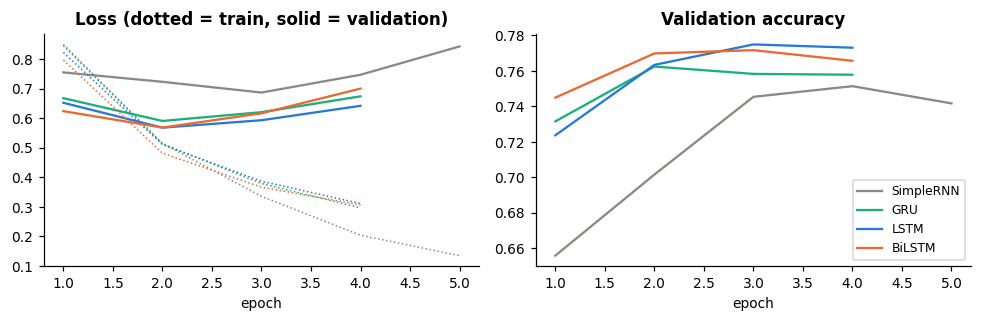

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
palette = dict(zip(ARCHS, [GREY, GREEN, BLUE, ORANGE]))
for name, h in histories.items():
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["loss"], color=palette[name], ls=":", lw=1)
    axes[0].plot(ep, h["val_loss"], color=palette[name], label=name)
    axes[1].plot(ep, h["val_accuracy"], color=palette[name], label=name)
axes[0].set_title("Loss (dotted = train, solid = validation)"); axes[0].set_xlabel("epoch")
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

Train loss (dotted) keeps falling; validation loss (solid) bottoms out after a few epochs and then rises. Early stopping keeps the weights from that bottom. The training loss is computed with class weights and dropout active, so compare the *shape* of the two curves, not their absolute levels.

### 5.5 What overfitting looks like  *(slide: Overfitting)*
Same LSTM, but bigger, no dropout and no early stopping.

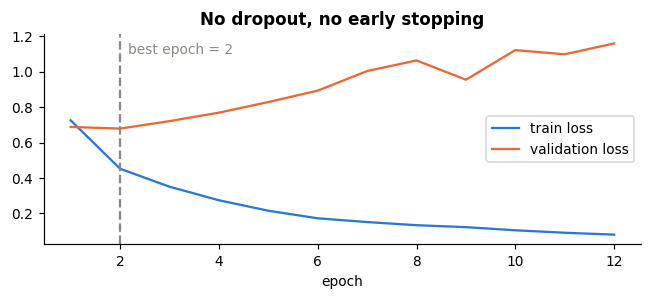

validation loss: best 0.679 at epoch 2, last 1.160
validation macro-F1 of the LAST epoch: 0.682  (compare with the table above)


In [ ]:
over_model, over_hist, over_row = train(dict(kind="LSTM", emb_dim=128, units=128, dropout=0.0, lr=2e-3, batch_size=64),
                                        epochs=12, early_stop=False)
ep = np.arange(1, len(over_hist["loss"]) + 1)
best_ep = int(np.argmin(over_hist["val_loss"])) + 1

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(ep, over_hist["loss"], color=BLUE, label="train loss")
ax.plot(ep, over_hist["val_loss"], color=ORANGE, label="validation loss")
ax.axvline(best_ep, color=GREY, ls="--"); ax.text(best_ep + 0.15, max(over_hist["val_loss"]) * 0.95, f"best epoch = {best_ep}", color=GREY)
ax.set_xlabel("epoch"); ax.legend(); ax.set_title("No dropout, no early stopping")
plt.tight_layout(); plt.show()

print(f"validation loss: best {min(over_hist['val_loss']):.3f} at epoch {best_ep}, last {over_hist['val_loss'][-1]:.3f}")
print(f"validation macro-F1 of the LAST epoch: {over_row['val_macro_f1']:.3f}  (compare with the table above)")
del over_model

The signature from the slide: training keeps improving while validation stops improving or gets worse. Responses, in the order we usually try them: early stopping, dropout, a smaller model, more or cleaner data. What we never do is pick the epoch or the model by looking at the **test** set.

Note that validation *loss* can worsen while macro-F1 stays roughly flat: the model becomes over-confident on the examples it gets wrong. Loss is the more sensitive signal for stopping; macro-F1 is the metric we report.

---
## 6. Hyperparameter tuning: finding the best settings
So far every model used hand-picked values (`emb_dim=64, units=64, dropout=0.3, lr=1e-3`). Tuning searches for better ones **using the validation set only**.

| Hyperparameter | What it controls | Typical range for tweets |
|---|---|---|
| `kind` | cell type | LSTM, GRU |
| `bidirectional` | read left→right only, or both ways | False / True |
| `emb_dim` | size of each word vector | 32 – 128 |
| `units` | size of the hidden state | 32 – 128 |
| `dropout` | regularization strength | 0.2 – 0.5 |
| `lr` | Adam learning rate (most sensitive!) | 3e-4 – 3e-3, sampled on a **log** scale |
| `batch_size` | examples per update | 32 – 128 |

**Why random search and not a full grid?** Seven hyperparameters with three values each is $3^7 = 2{,}187$ runs. Random search tries $N$ random combinations; because only a few hyperparameters usually matter, it explores each of them at more distinct values than a grid of the same cost (Bergstra & Bengio, 2012).

Rules we follow:
1. Define the search space **before** looking at results.
2. Select on **validation macro-F1**; the test set stays locked.
3. Re-check the top configurations with another seed, because the best of $N$ noisy runs is optimistically biased.

In [ ]:
SEARCH_SPACE = {
    "kind":          ["LSTM", "GRU"],
    "bidirectional": [False, True],
    "emb_dim":       [32, 64, 128],
    "units":         [32, 64, 128],
    "dropout":       [0.2, 0.3, 0.4, 0.5],
    "batch_size":    [32, 64, 128],
}
LR_RANGE = (3e-4, 3e-3)
N_TRIALS = 6 if FAST_DEMO else 12   # raise to 25–30 if you have time; each trial ≈ 10–40 s on a T4

def sample_config(rng):
    cfg = {k: v[rng.integers(len(v))] for k, v in SEARCH_SPACE.items()}
    cfg = {k: (v.item() if hasattr(v, "item") else v) for k, v in cfg.items()}   # NumPy → plain Python
    cfg["lr"] = float(round(10 ** rng.uniform(np.log10(LR_RANGE[0]), np.log10(LR_RANGE[1])), 5))
    return cfg

search_rng = np.random.default_rng(SEED)
configs = [sample_config(search_rng) for _ in range(N_TRIALS)]
pd.DataFrame(configs).head(4)

,kind,bidirectional,emb_dim,units,dropout,batch_size,lr
0,LSTM,True,64,64,0.3,128,0.00149
1,LSTM,False,64,128,0.4,128,0.00183
2,GRU,False,128,64,0.4,64,0.00253
3,GRU,True,64,128,0.4,64,0.00051


In [ ]:
trial_rows, trial_models = [], {}
t0 = time.time()
for i, cfg in enumerate(configs):
    model, hist, row = train(cfg, seed=SEED)
    trial_rows.append({"trial": i, **row})
    trial_models[i] = model
    print(f"trial {i:>2} | {cfg['kind']:<4} bi={str(cfg['bidirectional']):<5} emb={cfg['emb_dim']:<3} units={cfg['units']:<3} "
          f"drop={cfg['dropout']:.1f} lr={cfg['lr']:.5f} bs={cfg['batch_size']:<3} → val macro-F1 {row['val_macro_f1']:.3f} "
          f"({row['seconds']:.0f}s)")
print(f"search took {time.time() - t0:.0f}s")

trials = pd.DataFrame(trial_rows).sort_values("val_macro_f1", ascending=False)
cols = ["trial", "kind", "bidirectional", "emb_dim", "units", "dropout", "lr", "batch_size",
        "val_macro_f1", "best_epoch", "params", "seconds"]
display(trials[cols].head(8).style.format({"val_macro_f1": "{:.3f}", "lr": "{:.5f}", "params": "{:,}"})
        .background_gradient(subset=["val_macro_f1"], cmap="Blues"))

trial  0 | LSTM bi=True  emb=64  units=64  drop=0.3 lr=0.00149 bs=128 → val macro-F1 0.726 (6s)
trial  1 | LSTM bi=False emb=64  units=128 drop=0.4 lr=0.00183 bs=128 → val macro-F1 0.747 (6s)
trial  2 | GRU  bi=False emb=128 units=64  drop=0.4 lr=0.00253 bs=64  → val macro-F1 0.689 (6s)
trial  3 | GRU  bi=True  emb=64  units=128 drop=0.4 lr=0.00051 bs=64  → val macro-F1 0.730 (11s)
trial  4 | LSTM bi=True  emb=128 units=32  drop=0.5 lr=0.00128 bs=128 → val macro-F1 0.721 (7s)
trial  5 | LSTM bi=True  emb=128 units=64  drop=0.2 lr=0.00235 bs=128 → val macro-F1 0.744 (5s)
trial  6 | GRU  bi=True  emb=128 units=32  drop=0.3 lr=0.00033 bs=64  → val macro-F1 0.727 (14s)
trial  7 | GRU  bi=False emb=128 units=128 drop=0.5 lr=0.00278 bs=128 → val macro-F1 0.716 (4s)
trial  8 | LSTM bi=False emb=128 units=64  drop=0.2 lr=0.00046 bs=64  → val macro-F1 0.734 (6s)
trial  9 | LSTM bi=False emb=128 units=64  drop=0.3 lr=0.00140 bs=32  → val macro-F1 0.681 (10s)
trial 10 | GRU  bi=False emb=32  unit

,trial,kind,bidirectional,emb_dim,units,dropout,lr,batch_size,val_macro_f1,best_epoch,params,seconds
1,1,LSTM,False,64,128,0.400000,0.00183,128,0.747,2,"401,923",6.000000
5,5,LSTM,True,128,64,0.200000,0.00235,128,0.744,1,"704,643",4.900000
8,8,LSTM,False,128,64,0.200000,0.00046,64,0.734,2,"655,043",6.500000
11,11,GRU,True,64,128,0.500000,0.00058,64,0.730,3,"452,483",10.000000
3,3,GRU,True,64,128,0.400000,0.00051,64,0.730,3,"452,483",11.000000
6,6,GRU,True,128,32,0.300000,0.00033,64,0.727,3,"636,739",13.900000
0,0,LSTM,True,64,64,0.300000,0.00149,128,0.726,2,"369,155",6.100000
10,10,GRU,False,32,128,0.400000,0.00062,128,0.725,3,"213,955",5.400000


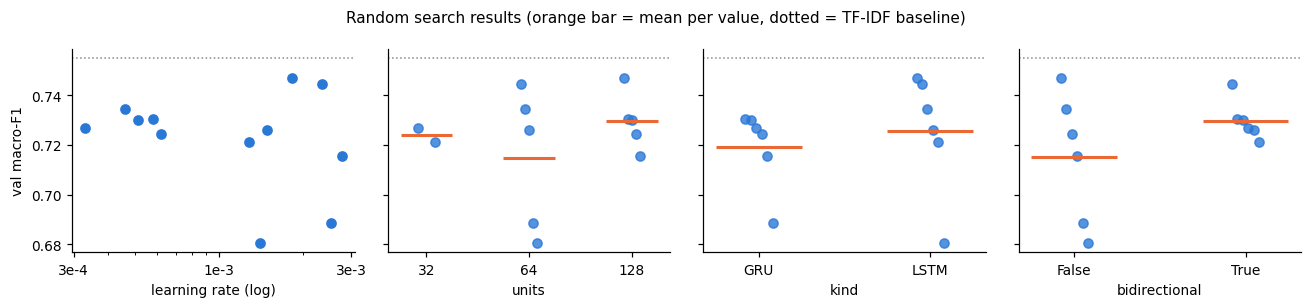

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
t = trials.copy()
axes[0].scatter(t["lr"], t["val_macro_f1"], color=BLUE)
axes[0].set_xscale("log"); axes[0].set_xlabel("learning rate (log)"); axes[0].set_ylabel("val macro-F1")
axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_xticks([3e-4, 1e-3, 3e-3], ["3e-4", "1e-3", "3e-3"])
for ax, col in zip(axes[1:], ["units", "kind", "bidirectional"]):
    groups = [g for g, _ in t.groupby(col)]
    for j, g in enumerate(groups):
        vals = t.loc[t[col] == g, "val_macro_f1"]
        ax.scatter(np.full(len(vals), j) + np.linspace(-0.08, 0.08, len(vals)), vals, color=BLUE, alpha=0.8)
        ax.hlines(vals.mean(), j - 0.25, j + 0.25, color=ORANGE, lw=2)
    ax.set_xticks(range(len(groups)), [str(g) for g in groups]); ax.set_xlabel(col)
for ax in axes:
    ax.axhline(BASELINE_VAL_F1, color=GREY, ls=":", lw=1)
fig.suptitle("Random search results (orange bar = mean per value, dotted = TF-IDF baseline)", fontsize=10)
plt.tight_layout(); plt.show()

With only a dozen trials these plots are **hints, not conclusions**: each value of `units` appears in a handful of trials, mixed with every other setting. What they are good for is spotting obviously bad regions (for example, a learning rate that is too small to converge within the epoch budget) and narrowing the space for a second, smaller search.

### 6.1 Is the winner real? Re-run the top configurations with new seeds

In [ ]:
TOP_K, CHECK_SEEDS = (2, [7]) if FAST_DEMO else (3, [7, 2024])
param_cols = ["kind", "bidirectional", "emb_dim", "units", "dropout", "lr", "batch_size"]
robust = []
for _, r in trials.head(TOP_K).iterrows():
    cfg = {c: (r[c].item() if hasattr(r[c], "item") else r[c]) for c in param_cols}
    scores = [r["val_macro_f1"]] + [train(cfg, seed=s)[2]["val_macro_f1"] for s in CHECK_SEEDS]
    robust.append({"trial": int(r["trial"]), **cfg, "f1_seed42": scores[0],
                   "f1_mean_seeds": np.mean(scores), "f1_std": np.std(scores, ddof=1)})
robust = pd.DataFrame(robust).sort_values("f1_mean_seeds", ascending=False)
display(robust.style.format({"lr": "{:.5f}", "f1_seed42": "{:.3f}", "f1_mean_seeds": "{:.3f}", "f1_std": "{:.3f}"}))

BEST_TRIAL = int(robust.iloc[0]["trial"])
BEST_CONFIG = {c: robust.iloc[0][c] for c in param_cols}
BEST_CONFIG = {k: (v.item() if hasattr(v, "item") else v) for k, v in BEST_CONFIG.items()}
print("Chosen configuration:", BEST_CONFIG)
drop = robust["f1_seed42"] - robust["f1_mean_seeds"]
print(f"Average drop from the seed-42 score to the multi-seed mean: {drop.mean():+.3f}  (> 0 means the search was a bit lucky)")

,trial,kind,bidirectional,emb_dim,units,dropout,lr,batch_size,f1_seed42,f1_mean_seeds,f1_std
1,5,LSTM,True,128,64,0.200000,0.00235,128,0.744,0.737,0.009
0,1,LSTM,False,64,128,0.400000,0.00183,128,0.747,0.733,0.013
2,8,LSTM,False,128,64,0.200000,0.00046,64,0.734,0.732,0.003


Chosen configuration: {'kind': 'LSTM', 'bidirectional': True, 'emb_dim': 128, 'units': 64, 'dropout': 0.2, 'lr': 0.00235, 'batch_size': 128}
Average drop from the seed-42 score to the multi-seed mean: +0.008  (> 0 means the search was a bit lucky)


We choose by the **mean over seeds**, not by the single best run. Typically the seed-42 scores of the top trials shrink a little when re-run: that shrinkage is the "winner's curse" of picking the maximum of noisy numbers, and it is the reason the test set must stay untouched until the very end.

### 6.2 The same search with KerasTuner (optional)
Libraries such as KerasTuner automate the loop above (and offer smarter strategies such as Hyperband or Bayesian optimisation). Set `RUN_KERAS_TUNER = True` to try it; it installs the package and runs its own random search. It optimises `val_loss` because macro-F1 is not a built-in Keras metric for integer labels.

In [ ]:
RUN_KERAS_TUNER = False

if RUN_KERAS_TUNER:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "keras-tuner"], check=True)
    import keras_tuner as kt

    def build_hp(hp):
        return make_model(kind=hp.Choice("kind", ["LSTM", "GRU"]),
                          bidirectional=hp.Boolean("bidirectional"),
                          emb_dim=hp.Choice("emb_dim", [32, 64, 128]),
                          units=hp.Choice("units", [32, 64, 128]),
                          dropout=hp.Float("dropout", 0.2, 0.5, step=0.1),
                          lr=hp.Float("lr", *LR_RANGE, sampling="log"))

    tuner = kt.RandomSearch(build_hp, objective="val_loss", max_trials=10, seed=SEED,
                            directory="kt_runs", project_name="w11_airline", overwrite=True)
    tuner.search(X_train, y_train, validation_data=(X_val, y_val), epochs=MAX_EPOCHS, batch_size=64,
                 class_weight=CLASS_WEIGHT, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])
    tuner.results_summary(3)
    kt_best = tuner.get_best_models(1)[0]
    print("KerasTuner best model, validation macro-F1:", round(macro_f1(kt_best, X_val, y_val), 3))
else:
    print("Skipped (set RUN_KERAS_TUNER = True to run).")

Skipped (set RUN_KERAS_TUNER = True to run).


---
## 7. Final evaluation on the test set (once)
Three candidates, all frozen before this point:
1. **TF-IDF + LR** with the C chosen on validation,
2. the **untuned LSTM** from part 5 (seed 42),
3. the **tuned** model: the chosen configuration's seed-42 run from the search.

In [ ]:
best_model = trial_models[BEST_TRIAL]
lstm_default = models_cmp["LSTM"]

proba = {"TF-IDF + LR": baseline.predict_proba(Xte_tfidf),
         "LSTM (untuned)": lstm_default.predict(X_test, batch_size=512, verbose=0),
         "Tuned " + best_model.name: best_model.predict(X_test, batch_size=512, verbose=0)}
pred = {k: v.argmax(1) for k, v in proba.items()}

final = pd.DataFrame({k: {"test macro-F1": f1_score(y_test, p, average="macro"),
                          "test accuracy": accuracy_score(y_test, p),
                          **{f"F1 {c}": s for c, s in zip(CLASSES, f1_score(y_test, p, average=None))}}
                      for k, p in pred.items()}).T
display(final.style.format("{:.3f}").highlight_max(subset=["test macro-F1"], color="#d6e6fa"))

,test macro-F1,test accuracy,F1 negative,F1 neutral,F1 positive
TF-IDF + LR,0.752,0.799,0.869,0.646,0.742
LSTM (untuned),0.705,0.756,0.843,0.589,0.682
Tuned BiLSTM,0.737,0.783,0.857,0.639,0.716


In [ ]:
# How sure are we about the difference? Paired bootstrap over test tweets.
TUNED = list(pred)[2]
boot_rng = np.random.default_rng(SEED)
n = len(y_test)
diffs = []
for _ in range(1000):
    idx = boot_rng.integers(0, n, n)
    diffs.append(f1_score(y_test[idx], pred[TUNED][idx], average="macro")
                 - f1_score(y_test[idx], pred["TF-IDF + LR"][idx], average="macro"))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"{TUNED} minus TF-IDF, test macro-F1: {np.mean(diffs):+.3f}  (95% bootstrap interval {lo:+.3f} to {hi:+.3f})")
print("→ the interval excludes 0: the difference is unlikely to be test-sample noise." if lo > 0 or hi < 0
      else "→ the interval includes 0: on this test set we cannot claim one is better.")

Tuned BiLSTM minus TF-IDF, test macro-F1: -0.015  (95% bootstrap interval -0.030 to +0.001)
→ the interval includes 0: on this test set we cannot claim one is better.


              precision    recall  f1-score   support

    negative      0.903     0.815     0.857      1363
     neutral      0.599     0.684     0.639       459
    positive      0.657     0.787     0.716       343

    accuracy                          0.783      2165
   macro avg      0.720     0.762     0.737      2165
weighted avg      0.800     0.783     0.788      2165



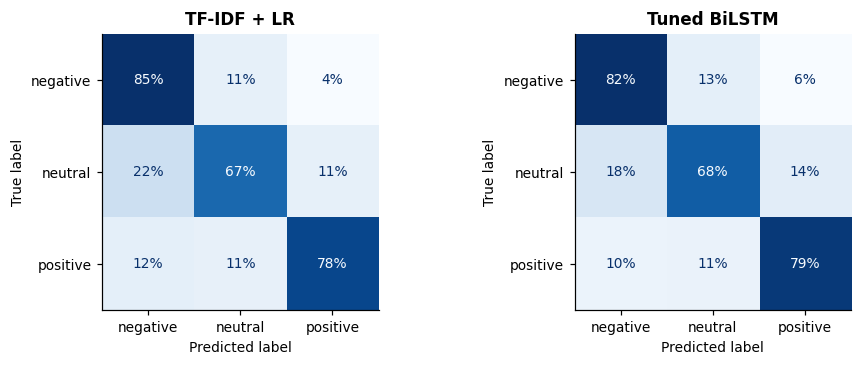

In [ ]:
print(classification_report(y_test, pred[TUNED], target_names=CLASSES, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, name in zip(axes, ["TF-IDF + LR", TUNED]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred[name], display_labels=CLASSES, normalize="true",
                                            values_format=".0%", cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

Rows are the true label, so the diagonal is recall per class. Most confusion is usually **neutral ↔ negative**: a factual question ("when does the gate open?") versus a polite complaint ("still waiting for an answer about my bag") can look alike.

### 7.1 Probing order sensitivity
Hand-written sentences in which word order or negation flips the meaning. TF-IDF with bigrams sees local order only; the recurrent model reads the full sequence. Neither is guaranteed to get these right; let's look.

In [ ]:
probes = ["the flight was late but the crew was amazing",
          "the crew was amazing but the flight was late",
          "not bad at all, smooth landing",
          "not good, still no bag",
          "thanks for nothing",
          "great, another delay. love it",
          "can you tell me if flight 123 is on time?"]
probe_tokens = [tokenize(p) for p in probes]
p_tfidf = baseline.predict_proba(tfidf.transform([join(t) for t in probe_tokens]))
p_rnn = best_model.predict(to_matrix(probe_tokens), verbose=0)
probe_df = pd.DataFrame({"text": probes,
                         "TF-IDF": [CLASSES[i] for i in p_tfidf.argmax(1)],
                         "P(neg) TF-IDF": p_tfidf[:, 0],
                         best_model.name: [CLASSES[i] for i in p_rnn.argmax(1)],
                         "P(neg) RNN": p_rnn[:, 0]})
display(probe_df.style.format({"P(neg) TF-IDF": "{:.2f}", "P(neg) RNN": "{:.2f}"}))

,text,TF-IDF,P(neg) TF-IDF,BiLSTM,P(neg) RNN
0,the flight was late but the crew was amazing,positive,0.26,positive,0.07
1,the crew was amazing but the flight was late,positive,0.26,positive,0.06
2,"not bad at all, smooth landing",negative,0.71,positive,0.42
3,"not good, still no bag",negative,0.97,negative,0.93
4,thanks for nothing,positive,0.36,positive,0.12
5,"great, another delay. love it",positive,0.03,positive,0.01
6,can you tell me if flight 123 is on time?,neutral,0.17,neutral,0.12


Questions for the class: do the first two sentences (same words, different order) get different scores from each model? Which model notices the sarcasm in "great, another delay"? Sarcasm usually defeats both, because the training data rarely labels it consistently.

### 7.2 Error analysis by slice  *(slide: Training Workflow: pair metrics with error analysis)*

In [ ]:
NEGATIONS = {"not", "no", "never", "don't", "didn't", "can't", "won't", "isn't", "wasn't", "nothing", "cannot"}
CONTRAST = {"but", "however", "although", "though", "yet"}
te = test_df.assign(y=y_test, tfidf=pred["TF-IDF + LR"], rnn=pred[TUNED], n_tok=test_df["tokens"].str.len())
slices = {
    "all": np.ones(len(te), bool),
    "has negation": te["tokens"].map(lambda t: bool(NEGATIONS & set(t))).values,
    "has contrast (but/however…)": te["tokens"].map(lambda t: bool(CONTRAST & set(t))).values,
    "question (?)": te["tokens"].map(lambda t: "?" in t).values,
    "short (≤ 10 tokens)": (te["n_tok"] <= 10).values,
    "long (≥ 25 tokens)": (te["n_tok"] >= 25).values,
}
rows = []
for name, mask in slices.items():
    s = te[mask]
    rows.append({"slice": name, "n": int(mask.sum()),
                 "TF-IDF macro-F1": f1_score(s["y"], s["tfidf"], average="macro"),
                 "RNN macro-F1": f1_score(s["y"], s["rnn"], average="macro")})
slice_df = pd.DataFrame(rows).set_index("slice").assign(diff=lambda d: d["RNN macro-F1"] - d["TF-IDF macro-F1"])
display(slice_df.style.format({"TF-IDF macro-F1": "{:.3f}", "RNN macro-F1": "{:.3f}", "diff": "{:+.3f}"})
        .bar(subset=["diff"], align="zero", color=[ORANGE, BLUE]))

,n,TF-IDF macro-F1,RNN macro-F1,diff
slice,,,,
all,2165,0.752,0.737,-0.015
has negation,648,0.648,0.646,-0.002
has contrast (but/however…),229,0.684,0.628,-0.056
question (?),542,0.658,0.608,-0.050
short (≤ 10 tokens),362,0.758,0.702,-0.056
long (≥ 25 tokens),392,0.702,0.721,+0.019


Slices with small `n` are noisy (a few dozen tweets can swing F1 by several points), so treat a positive `diff` on a small slice as a hypothesis to test, not a result. Where does sequence modelling seem to help, and where not?

The most informative errors are the ones the model is **confident** about:

In [ ]:
p_best = proba[TUNED]
te["pred"] = [CLASSES[i] for i in pred[TUNED]]
te["confidence"] = p_best.max(1)
wrong = te[te["pred"] != te["label"]].sort_values("confidence", ascending=False)
display(wrong[["text", "label", "pred", "confidence"]].head(10).style.format({"confidence": "{:.2f}"}))

,text,label,pred,confidence
8936,"@JetBlue Ok great thanks! I had a great flight, FYI. I'm excited to fly again. I just was frustrated I was not able to check in.",neutral,positive,0.99
989,"@united Thank you, ^JH, appreciate the prompt responses--me and other passengers will be doing so.",neutral,positive,0.98
2008,@united Thanks! Good to know.,neutral,positive,0.97
9010,@USAirways we even offered to fly in to another airport and they said they couldn't do that. No explanation why they can't.,neutral,negative,0.97
4271,@united thank you!!!!! And next flight to Durango then driving to Farmington New Mexico for work! But hitting the slopes in Durango!,neutral,positive,0.96
2850,@united thanks for reminding me how much easier it is to fly Southwest! Get more agents at sfo 25!,negative,positive,0.96
6464,@SouthwestAir thanks! I expected a wait... Just not that long. :),negative,positive,0.95
12213,@AmericanAir Thank you for responding so quickly to my tweets I do appreciate that.,neutral,positive,0.95
8054,@JetBlue's CEO battles to appease passengers and Wall Street - Waterbury Republican American http://t.co/Ur60Un86gy,negative,neutral,0.95
8292,@JetBlue I can probably find some of them. Are the ticket #s on there?,negative,neutral,0.95


Look for patterns rather than single mistakes. Common ones in this dataset: label noise (the human label is arguable), sarcasm, tweets that mention a complaint but thank the airline for fixing it, and neutral questions written in an annoyed tone. Each pattern points to a different fix: relabelling, more examples, or accepting the limit.

### 7.3 A look inside the LSTM gates
To connect the slides' gate diagrams to the trained model, we take the untuned **LSTM** from part 5, pull its weights out of Keras and recompute the forward pass in NumPy. Keras stores the four gate blocks side by side in the order **input, forget, candidate, output**.

In [ ]:
sig = lambda z: 1 / (1 + np.exp(-z))

emb_layer, lstm_layer, _, dense_layer = [l for l in lstm_default.layers
                                         if not isinstance(l, keras.layers.InputLayer)]
E_w = emb_layer.get_weights()[0]
W, U, b_l = lstm_layer.get_weights()                  # kernel (d, 4u), recurrent (u, 4u), bias (4u,)
W_out, b_out = dense_layer.get_weights()
UNITS = U.shape[0]

def lstm_trace(tokens):
    """Run the trained LSTM in NumPy, returning per-token gates and the running class probabilities."""
    ids = encode(tokens)[:MAX_LEN]
    h, c = np.zeros(UNITS), np.zeros(UNITS)
    rows = []
    for tok, i in zip(tokens, ids):
        z = E_w[i] @ W + h @ U + b_l
        i_g, f_g, g, o_g = sig(z[:UNITS]), sig(z[UNITS:2*UNITS]), np.tanh(z[2*UNITS:3*UNITS]), sig(z[3*UNITS:])
        c = f_g * c + i_g * g                         # forget old memory, write new
        h = o_g * np.tanh(c)                          # show part of the memory
        logits = h @ W_out + b_out
        p = np.exp(logits - logits.max()); p /= p.sum()
        rows.append({"token": tok, "forget": f_g.mean(), "input": i_g.mean(), "output": o_g.mean(),
                     **{f"P({k})": v for k, v in zip(CLASSES, p)}})
    return pd.DataFrame(rows)

sentence = "the crew was amazing but the flight was cancelled and nobody helped"
trace = lstm_trace(tokenize(sentence))
keras_p = lstm_default.predict(to_matrix([tokenize(sentence)]), verbose=0)[0]
numpy_p = trace[[f"P({k})" for k in CLASSES]].iloc[-1].values
print("Keras  :", np.round(keras_p, 4))
print("NumPy  :", np.round(numpy_p, 4))
print("Same?  ", np.allclose(keras_p, numpy_p, atol=1e-4))

Keras  : [0.1759 0.036  0.7882]
NumPy  : [0.1759 0.036  0.7882]
Same?   True


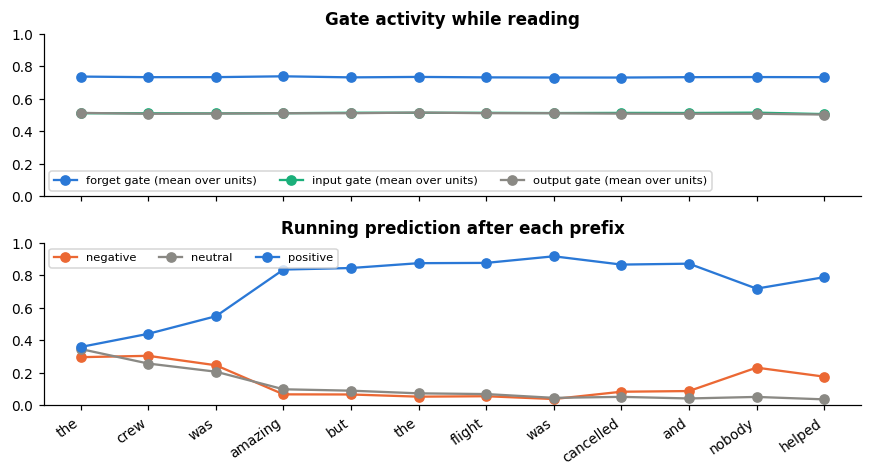

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.4), sharex=True)
x = np.arange(len(trace))
for col, c in [("forget", BLUE), ("input", GREEN), ("output", GREY)]:
    axes[0].plot(x, trace[col], marker="o", color=c, label=f"{col} gate (mean over units)")
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=7.5, ncol=3, loc="lower left"); axes[0].set_title("Gate activity while reading")
for k in CLASSES:
    axes[1].plot(x, trace[f"P({k})"], marker="o", color=CLASS_COLORS[k], label=k)
axes[1].set_ylim(0, 1); axes[1].legend(fontsize=7.5, ncol=3, loc="upper left")
axes[1].set_title("Running prediction after each prefix")
axes[1].set_xticks(x, trace["token"], rotation=35, ha="right")
plt.tight_layout(); plt.show()

- The NumPy result equals the Keras prediction: the LSTM is just the slide's equations applied token by token. Because we feed only the real tokens, this also shows what masking achieves.
- The bottom panel is the LSTM intuition slide in action: watch whether the prediction moves after the contrast word "but" and the negative evidence that follows.
- Gate averages hide a lot (each of the units has its own gates), so do not over-interpret small wiggles. Interpretability research uses far more careful tools; this is a teaching view.

Try your own sentence, e.g. the reverse order: `"the flight was cancelled but the crew was amazing"`.

---
## 8. Integrating sequence NLP and SNA  *(section 03 of the slides)*
The recurrent model supplies **content labels** for every post; network analysis supplies **structural context** for every account. Joined on `user_id`, they answer questions neither can answer alone: *Is negativity concentrated in one community? Are the accounts that connect communities spreading complaints?*

### 8.1 Three tables: posts, users, edges  *(slide: Data Model)*
We label **every** tweet with the tuned model. For the 70% of tweets the model was trained on, these predictions are in-sample and therefore optimistic; we check below that the predicted negative rate matches the human labels.

In [ ]:
X_all = to_matrix(df["tokens"].tolist())
p_all = best_model.predict(X_all, batch_size=512, verbose=0)

posts = pd.DataFrame({
    "post_id": df["tweet_id"].values,
    "user_id": df["user"].values,
    "text": df["text"].values,
    "timestamp": pd.to_datetime(df["tweet_created"].str[:19]).values,
    "predicted_sentiment": [CLASSES[i] for i in p_all.argmax(1)],
    "p_negative": p_all[:, 0],
    "human_label": df["label"].values,
})
in_test = posts["post_id"].isin(test_df["tweet_id"])
print(f"negative share  | human labels: {(posts['human_label'] == 'negative').mean():.1%}"
      f" | predicted (all): {(posts['predicted_sentiment'] == 'negative').mean():.1%}"
      f" | predicted (test only): {(posts.loc[in_test, 'predicted_sentiment'] == 'negative').mean():.1%}")
posts.head(3)

negative share  | human labels: 62.9% | predicted (all): 57.4% | predicted (test only): 56.8%


,post_id,user_id,text,timestamp,predicted_sentiment,p_negative,human_label
0,570306133677760513,cairdin,@VirginAmerica What @dhepburn said.,2015-02-24 11:35:52,neutral,0.144494,neutral
1,570301130888122368,jnardino,@VirginAmerica plus you've added commercials to the experience... tacky.,2015-02-24 11:15:59,positive,0.277675,positive
2,570301083672813571,yvonnalynn,@VirginAmerica I didn't today... Must mean I need to take another trip!,2015-02-24 11:15:48,neutral,0.183920,neutral


**Edges** come from @mentions: author → mentioned account. Almost every tweet mentions an airline, so the network is a set of airline "hubs" with their customers around them, plus a minority of customer-to-customer and customer-to-media mentions.

Data-quality note: in this dataset the `airline` column says *Delta* for tweets that are actually addressed to **@JetBlue**. We therefore name accounts by the handles in the text, not by that column.

In [ ]:
AIRLINE_HANDLES = {"united", "usairways", "americanair", "southwestair", "jetblue", "virginamerica", "delta"}

mentions = (posts[["post_id", "user_id", "text", "timestamp"]]
            .assign(target_user=posts["text"].str.lower().str.findall(r"@(\w+)"))
            .explode("target_user").dropna(subset=["target_user"]))
mentions = mentions[mentions["user_id"] != mentions["target_user"]]

edges = (mentions.groupby(["user_id", "target_user"])
         .agg(weight=("post_id", "size"), first_seen=("timestamp", "min")).reset_index()
         .rename(columns={"user_id": "source_user"}).assign(interaction_type="mention"))
print(f"{len(mentions):,} mentions → {len(edges):,} weighted edges")
print(f"mentions of airline accounts: {mentions['target_user'].isin(AIRLINE_HANDLES).mean():.1%}")
edges.sort_values("weight", ascending=False).head(5)

16,120 mentions → 9,246 weighted edges
mentions of airline accounts: 92.6%


,source_user,target_user,weight,first_seen,interaction_type
4114,jetbluenews,jetblue,64,2015-02-16 23:36:05,mention
4683,kbosspotter,jetblue,33,2015-02-17 08:49:16,mention
6583,otisday,americanair,28,2015-02-22 12:22:19,mention
8524,throthra,united,27,2015-02-21 18:27:53,mention
126,_mhertz,united,24,2015-02-20 08:43:46,mention


In [ ]:
G = nx.Graph()
for r in edges.itertuples(index=False):
    if G.has_edge(r.source_user, r.target_user):           # A→B and B→A collapse into one undirected tie
        G[r.source_user][r.target_user]["weight"] += r.weight
    else:
        G.add_edge(r.source_user, r.target_user, weight=r.weight)
print(f"nodes {G.number_of_nodes():,} | edges {G.number_of_edges():,} | components {nx.number_connected_components(G):,}")

communities = nx.community.louvain_communities(G, weight="weight", resolution=1.0, seed=SEED)
communities = sorted(communities, key=len, reverse=True)
community_of = {n: cid for cid, members in enumerate(communities) for n in members}
print(f"Louvain: {len(communities):,} communities, modularity {nx.community.modularity(G, communities, weight='weight'):.3f}")

t0 = time.time()
betweenness = nx.betweenness_centrality(G, k=min(500, G.number_of_nodes()), seed=SEED)   # sampled: fast approximation
pagerank = nx.pagerank(G, weight="weight")
print(f"centralities computed in {time.time() - t0:.0f}s")

users = pd.DataFrame({"user_id": list(G.nodes())})
users["community"] = users["user_id"].map(community_of)
users["degree"] = users["user_id"].map(dict(G.degree()))
users["betweenness"] = users["user_id"].map(betweenness)
users["pagerank"] = users["user_id"].map(pagerank)
users["is_airline"] = users["user_id"].isin(AIRLINE_HANDLES)
users.sort_values("pagerank", ascending=False).head(8)

nodes 8,279 | edges 9,234 | components 1
Louvain: 26 communities, modularity 0.764
centralities computed in 14s


,user_id,community,degree,betweenness,pagerank,is_airline
18,united,0,2014,0.414222,0.107764,True
6,southwestair,1,1646,0.390676,0.083318,True
11,usairways,3,1496,0.311083,0.076674,True
13,americanair,2,1427,0.314497,0.071557,True
15,jetblue,4,1144,0.256287,0.061621,True
8,virginamerica,5,404,0.082668,0.019597,True
3743,jetbluenews,4,12,0.001771,0.001885,False
292,delta,6,59,0.003950,0.001550,True


`betweenness_centrality(k=500)` estimates betweenness from 500 sampled source nodes instead of all 8,000+; rankings of the top accounts are stable, exact values are approximate (week 9).

### 8.2 Sentiment by community  *(slide: Example: Sentiment by Community)*
Name each large community by its most central account, then aggregate the predicted sentiment of posts written by its members.

6 of 26 communities have ≥ 100 posts


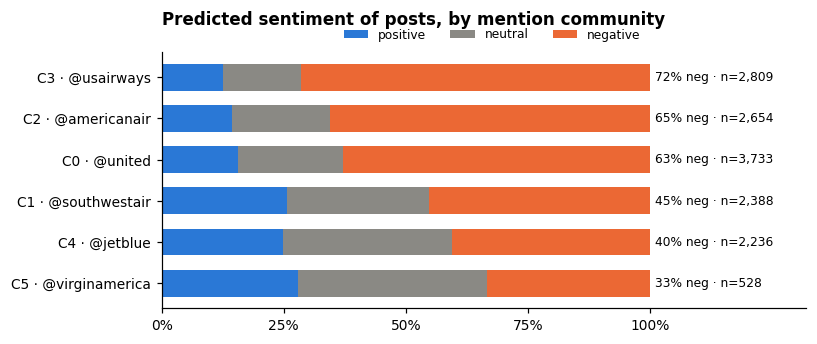

In [ ]:
posts["community"] = posts["user_id"].map(community_of)
hub_of = (users.sort_values("pagerank", ascending=False).groupby("community")["user_id"].first())

MIN_POSTS = 100                                         # small communities give unstable percentages
size = posts["community"].value_counts()
big = size[size >= MIN_POSTS].index
print(f"{len(big)} of {posts['community'].nunique()} communities have ≥ {MIN_POSTS} posts")
by_comm = (pd.crosstab(posts.loc[posts["community"].isin(big), "community"],
                       posts.loc[posts["community"].isin(big), "predicted_sentiment"], normalize="index")
           .reindex(columns=CLASSES))
by_comm["n_posts"] = posts["community"].value_counts().reindex(by_comm.index)
by_comm.index = [f"C{c} · @{hub_of[c]}" for c in by_comm.index]
by_comm = by_comm.sort_values("negative")

fig, ax = plt.subplots(figsize=(7.5, 3.2))
left = np.zeros(len(by_comm))
for k in ["positive", "neutral", "negative"]:
    ax.barh(by_comm.index, by_comm[k], left=left, color=CLASS_COLORS[k], label=k, height=0.65)
    left += by_comm[k].values
for y, (neg, n) in enumerate(zip(by_comm["negative"], by_comm["n_posts"])):
    ax.text(1.01, y, f"{neg:.0%} neg · n={n:,}", va="center", fontsize=8)
ax.set_xlim(0, 1.32); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.legend(ncol=3, fontsize=8, loc="lower right", bbox_to_anchor=(0.76, 1.0), frameon=False)
ax.set_title("Predicted sentiment of posts, by mention community", loc="left", pad=18)
plt.tight_layout(); plt.show()

In [ ]:
neg_overall = (posts["predicted_sentiment"] == "negative").mean()
most, least = by_comm.index[-1], by_comm.index[0]
print(f"Overall predicted negative share: {neg_overall:.0%}")
print(f"Most negative large community : {most} ({by_comm.loc[most, 'negative']:.0%} of {by_comm.loc[most, 'n_posts']:,} posts)")
print(f"Least negative large community: {least} ({by_comm.loc[least, 'negative']:.0%} of {by_comm.loc[least, 'n_posts']:,} posts)")

Overall predicted negative share: 57%
Most negative large community : C3 · @usairways (72% of 2,809 posts)
Least negative large community: C5 · @virginamerica (33% of 528 posts)


The slide's lesson: *the same overall negative percentage can require different actions depending on where the discussion is concentrated.* Here a community is essentially "the people who talk to this airline", so the chart is also a **brand comparison** built from network structure and model labels, with no use of the `airline` column.

### 8.3 Join predictions with network features  *(slide: Join predictions with network features)*
The slide's code, applied to our tables. Airline accounts are removed: we want to find **customers** who are both central and negative.

In [ ]:
profile = (posts
    .groupby("user_id")
    .agg(neg_rate=("predicted_sentiment", lambda x: (x == "negative").mean()),
         n_posts=("text", "size"))
    .reset_index())
# Two extra columns we can afford because this dataset is labelled: the human negative rate,
# and how often an account repeats the same message to different accounts (copy-paste / automation).
stripped = posts["text"].str.replace(r"@\w+", "", regex=True).str.strip().str.lower()
profile = profile.merge(
    posts.assign(stripped=stripped).groupby("user_id")
         .agg(human_neg_rate=("human_label", lambda x: (x == "negative").mean()),
              copy_paste=("stripped", lambda x: x.duplicated(keep=False).mean()))
         .reset_index(), on="user_id")
profile = profile.merge(users, on="user_id", how="left")
profile = profile[~profile["is_airline"].fillna(False).astype(bool)]

airlines_mentioned = (mentions[mentions["target_user"].isin(AIRLINE_HANDLES)]
                      .groupby("user_id")["target_user"].nunique().rename("n_airlines"))
profile = profile.merge(airlines_mentioned, on="user_id", how="left").fillna({"n_airlines": 0})

deg_q75 = profile["degree"].quantile(0.75)
watch = profile.query("degree > @deg_q75 and neg_rate > 0.5 and n_posts >= 2")
print(f"degree 75th percentile = {deg_q75:.0f}; {len(watch):,} central, mostly-negative customers with ≥ 2 posts")
display(watch.sort_values("betweenness", ascending=False)
        [["user_id", "n_posts", "neg_rate", "human_neg_rate", "degree", "n_airlines", "betweenness", "community"]]
        .head(10).style.format({"neg_rate": "{:.0%}", "human_neg_rate": "{:.0%}", "betweenness": "{:.5f}",
                                "n_airlines": "{:.0f}"}))

degree 75th percentile = 1; 339 central, mostly-negative customers with ≥ 2 posts


,user_id,n_posts,neg_rate,human_neg_rate,degree,n_airlines,betweenness,community
749,betorides,7,71%,86%,4,4,0.01315,2
5147,mycustoadvocate,4,100%,25%,4,4,0.01315,4
2388,faultie,2,100%,100%,3,3,0.00724,1
7093,throthra,27,81%,89%,5,4,0.00689,0
2708,gregm528,8,75%,100%,5,3,0.00687,3
5620,peterfransson,4,75%,0%,3,3,0.00666,3
1831,deniseimperial,3,100%,100%,3,3,0.00642,4
2353,fahadhassan,9,78%,78%,3,3,0.00625,3
1233,chagaga2013,14,93%,100%,4,3,0.00470,2
5148,mydulcebella,7,71%,71%,3,3,0.00408,3


Most customers mention a single airline, so the degree threshold is low; adding `n_posts >= 2` keeps one-off tweets out of the watch list. `human_neg_rate` is a luxury of a labelled dataset: where it disagrees strongly with `neg_rate`, the model is wrong about that account. Before acting on any name in this table, read their posts: a high negative rate from two tweets is thin evidence.

### 8.4 Bridge accounts carrying negative content  *(slides: Influential Users by Sentiment, Bridge Accounts)*
A customer who talks to two or more airlines connects those audiences in the mention network. Below: the airlines plus every such bridge customer. **Size = betweenness, colour = share of the account's posts predicted negative.**

423 bridge customers (mention ≥ 2 airlines) | their negative rate: 55% vs 52% for single-airline customers


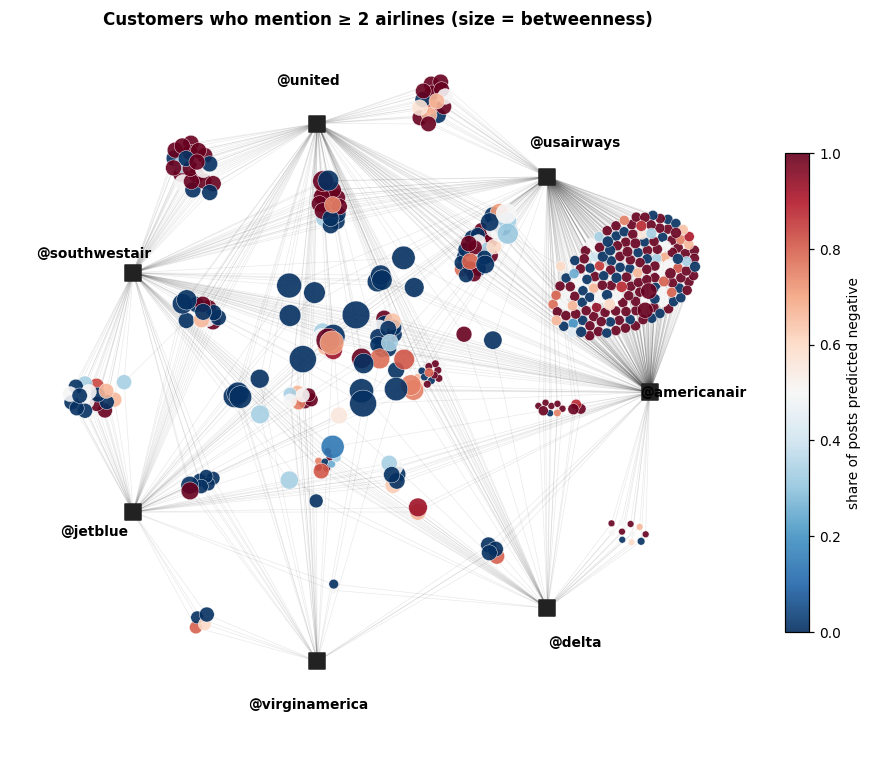

Most common airline combinations among bridge customers:
target_user
americanair + usairways    160
americanair + united        26
southwestair + united       24


In [ ]:
bridges = profile[profile["n_airlines"] >= 2]
print(f"{len(bridges):,} bridge customers (mention ≥ 2 airlines) | their negative rate: {bridges['neg_rate'].mean():.0%}"
      f" vs {profile.loc[profile['n_airlines'] == 1, 'neg_rate'].mean():.0%} for single-airline customers")

CIRCLE_ORDER = ["americanair", "usairways", "united", "southwestair", "jetblue", "virginamerica", "delta"]
air_nodes = [a for a in CIRCLE_ORDER if a in G]            # neighbours on the circle = often mentioned together
H = G.subgraph(set(bridges["user_id"]) | set(air_nodes)).copy()
H.remove_nodes_from([n for n in list(H) if H.degree(n) == 0])
neg_of = profile.set_index("user_id")["neg_rate"]

# Airlines fixed on a circle; customers settle between the airlines they mention.
angles = np.linspace(0, 2 * np.pi, len(air_nodes), endpoint=False)
fixed = {a: (np.cos(t), np.sin(t)) for a, t in zip(air_nodes, angles)}
pos = nx.spring_layout(H, pos=fixed, fixed=air_nodes, seed=SEED, k=0.08, iterations=200, weight=None)

fig, ax = plt.subplots(figsize=(8, 7))
nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.08, width=0.5)
cust = sorted((n for n in H if n not in AIRLINE_HANDLES), key=lambda n: betweenness.get(n, 0))
b = np.array([betweenness.get(n, 0) for n in cust])
sc = nx.draw_networkx_nodes(H, pos, nodelist=cust, ax=ax, node_color=[neg_of.get(n, 0) for n in cust],
                            cmap="RdBu_r", vmin=0, vmax=1, node_size=8 + 320 * np.sqrt(b / max(b.max(), 1e-12)),
                            linewidths=0.3, edgecolors="white", alpha=0.9)
nx.draw_networkx_nodes(H, pos, nodelist=air_nodes, ax=ax, node_shape="s", node_color="#222222", node_size=120)
for a in air_nodes:
    x, y = pos[a]
    ax.text(x * 1.16, y * 1.16, "@" + a, ha="center", va="center", fontsize=9, fontweight="bold")
plt.colorbar(sc, ax=ax, fraction=0.03, shrink=0.7, label="share of posts predicted negative")
ax.set_title("Customers who mention ≥ 2 airlines (size = betweenness)"); ax.axis("off")
ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.3, 1.3)
plt.tight_layout(); plt.show()

airline_sets = (mentions[mentions["target_user"].isin(AIRLINE_HANDLES)]
                .groupby("user_id")["target_user"].agg(lambda x: " + ".join(sorted(set(x)))))
print("Most common airline combinations among bridge customers:")
print(airline_sets[airline_sets.str.contains("+", regex=False)].value_counts().head(3).to_string())

In [ ]:
fmt = {"neg_rate": "{:.0%}", "human_neg_rate": "{:.0%}", "copy_paste": "{:.0%}", "betweenness": "{:.5f}", "n_airlines": "{:.0f}"}
show_cols = ["user_id", "n_posts", "n_airlines", "neg_rate", "human_neg_rate", "copy_paste", "betweenness"]
print("Top bridges by betweenness")
display(bridges.sort_values("betweenness", ascending=False)[show_cols].head(8).style.format(fmt))

Top bridges by betweenness


,user_id,n_posts,n_airlines,neg_rate,human_neg_rate,copy_paste,betweenness
1986,dontenphoto,13,5,0%,8%,0%,0.02359
3331,jeokoo1,3,5,0%,0%,100%,0.02146
2976,idk_but_youtube,5,5,0%,0%,80%,0.02082
1741,davidalfieward,4,4,0%,0%,100%,0.01522
3233,jayw329,4,5,0%,100%,0%,0.01339
5147,mycustoadvocate,4,4,100%,25%,50%,0.01315
749,betorides,7,4,71%,86%,29%,0.01315
1700,danteusa1,4,4,0%,25%,100%,0.01246


The biggest cluster of bridges sits between **@americanair and @usairways**: the two airlines were in the middle of merging, so many customers addressed both. A structural "bridge" can simply reflect a business fact.

Read who the top bridges actually are before calling them influential. In this dataset many of the highest-betweenness accounts are **not unhappy customers**: plane-spotting accounts that tag every airline and airport they photograph, app promoters, and accounts that paste the same message to every airline (high `copy_paste`). Structurally they are bridges; their content is mostly neutral and nobody necessarily reads it. This is the slide's question in practice: *amplifier, bridge, or simply active?*

So we filter: bridges whose posts are mostly negative, with at least two posts and little copy-pasting.

In [ ]:
negative_bridges = (bridges.query("neg_rate > 0.5 and n_posts >= 2 and copy_paste < 0.5")
                    .sort_values("betweenness", ascending=False))
print(f"{len(negative_bridges)} negative bridge customers")
display(negative_bridges[show_cols].head(8).style.format(fmt))
if len(negative_bridges):
    example_user = negative_bridges.iloc[0]["user_id"]
    print(f"Posts by {example_user}:")
    display(posts.loc[posts["user_id"] == example_user, ["timestamp", "predicted_sentiment", "human_label", "text"]]
            .sort_values("timestamp").head(6))

147 negative bridge customers


,user_id,n_posts,n_airlines,neg_rate,human_neg_rate,copy_paste,betweenness
749,betorides,7,4,71%,86%,29%,0.01315
2388,faultie,2,3,100%,100%,0%,0.00724
7093,throthra,27,4,81%,89%,0%,0.00689
2708,gregm528,8,3,75%,100%,0%,0.00687
5620,peterfransson,4,3,75%,0%,0%,0.00666
1831,deniseimperial,3,3,100%,100%,0%,0.00642
2353,fahadhassan,9,3,78%,78%,0%,0.00625
1233,chagaga2013,14,3,93%,100%,0%,0.00470


Posts by betorides:


,timestamp,predicted_sentiment,human_label,text
7609,2015-02-22 04:50:45,positive,positive,"@JetBlue FLL to MDE, great flight, great customer service, THANKS! 2 mths waiting @AmericanAir to speak..."
7604,2015-02-22 05:29:20,positive,negative,"@JetBlue I travel for business twice a week and after the @AmericanAir fiasco, I'll be flying blue more of..."
5023,2015-02-22 05:59:51,negative,negative,@SouthwestAir no HUMAN contact for 2 mths from @AmericanAir cust relations or refund dept. If ever a probl...
1971,2015-02-22 06:00:24,negative,negative,@united no HUMAN contact for 2 mths from @AmericanAir cust relations or refund dept. If ever a problem do ...
12114,2015-02-24 07:05:20,negative,negative,"@AmericanAir Just got a call from baggage dept. ""...still looking for your property"". It's went missing 1/..."
12107,2015-02-24 07:12:53,negative,negative,@AmericanAir over 70 days no contact from a human or apology letter. @AmericanAir is #yucki. Read all abo...
